In [1]:

import pandas as pd
import numpy as np

orders = pd.read_csv('/content/orders.csv')
products = pd.read_csv('/content/products.csv')
customers = pd.read_csv('/content/customers.csv')
delivery = pd.read_csv('/content/delivery.csv')
returns = pd.read_csv('/content/returns.csv')

print("All datasets loaded successfully!")
print("Orders:", orders.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Delivery:", delivery.shape)
print("Returns:", returns.shape)


All datasets loaded successfully!
Orders: (503, 7)
Products: (80, 5)
Customers: (220, 4)
Delivery: (503, 4)
Returns: (130, 4)


In [2]:

datasets = {
    'Orders': orders,
    'Products': products,
    'Customers': customers,
    'Delivery': delivery,
    'Returns': returns
}

for name, df in datasets.items():
    print(f"\n{name} - Missing Values")
    print(df.isnull().sum())



Orders - Missing Values
order_id       0
order_date     0
product_id     0
customer_id    0
quantity       0
price          0
discount       0
dtype: int64

Products - Missing Values
product_id    0
category      0
brand         0
size          0
seller_id     0
dtype: int64

Customers - Missing Values
customer_id         0
region              0
order_history       0
customer_segment    0
dtype: int64

Delivery - Missing Values
order_id          0
promised_date     0
delivered_date    0
courier           0
dtype: int64

Returns - Missing Values
order_id         0
return_flag      0
return_reason    6
return_date      0
dtype: int64


In [3]:

print("Duplicate orders:", orders.duplicated().sum())
print("Duplicate order IDs:", orders['order_id'].duplicated().sum())

orders = orders.drop_duplicates(subset='order_id', keep='first')
products = products.drop_duplicates(subset='product_id', keep='first')
customers = customers.drop_duplicates(subset='customer_id', keep='first')
delivery = delivery.drop_duplicates(subset='order_id', keep='first')
returns = returns.drop_duplicates(subset='order_id', keep='first')

print("\nDuplicates removed.")
print("Orders after cleaning:", orders.shape)


Duplicate orders: 3
Duplicate order IDs: 3

Duplicates removed.
Orders after cleaning: (500, 7)


In [4]:

# Fill missing categorical values
products['size'] = products['size'].fillna('Unknown')
customers['region'] = customers['region'].fillna('Unknown')
customers['customer_segment'] = customers['customer_segment'].fillna('Unknown')
returns['return_reason'] = returns['return_reason'].fillna('Not Specified')

# Fill missing numerical values with the median
for col in ['quantity', 'price', 'discount']:
    orders[col] = orders[col].fillna(orders[col].median())

print("Missing values handled.")


Missing values handled.


/tmp/ipykernel_707/2861143657.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  orders[col] = orders[col].fillna(orders[col].median())


In [5]:

products['size'] = (
    products['size']
    .astype(str)
    .str.strip()
    .str.upper()
    .replace({
        'MEDIUM': 'M',
        'SMALL': 'S',
        'X-LARGE': 'XL',
        'ONE SIZE': 'ONE SIZE'
    })
)

print(products['size'].value_counts())


size
XL          14
L           14
XS          13
S           12
M           10
XXL          9
ONE SIZE     8
Name: count, dtype: int64


In [6]:

delivery['promised_date'] = pd.to_datetime(
    delivery['promised_date'], errors='coerce'
)

delivery['delivered_date'] = pd.to_datetime(
    delivery['delivered_date'], errors='coerce'
)

delivery['delivery_delay'] = (
    delivery['delivered_date'] - delivery['promised_date']
).dt.days

print("Invalid promised dates:", delivery['promised_date'].isna().sum())
print("Invalid delivered dates:", delivery['delivered_date'].isna().sum())
print(delivery[['order_id', 'delivery_delay']].head())


Invalid promised dates: 1
Invalid delivered dates: 1
  order_id  delivery_delay
0   O00001             2.0
1   O00002             2.0
2   O00003             7.0
3   O00004            -1.0
4   O00005             7.0


/tmp/ipykernel_707/2892208414.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivery['promised_date'] = pd.to_datetime(
/tmp/ipykernel_707/2892208414.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivery['delivered_date'] = pd.to_datetime(
/tmp/ipykernel_707/2892208414.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-doc

In [7]:

print("Discount values before cleaning:")
print(orders['discount'].describe())

# Valid discounts should be between 0 and 100
orders.loc[
    ~orders['discount'].between(0, 100),
    'discount'
] = np.nan

orders['discount'] = orders['discount'].fillna(
    orders['discount'].median()
)

print("\nDiscount values after cleaning:")
print(orders['discount'].describe())


Discount values before cleaning:
count    500.00000
mean      13.38000
std       11.16355
min      -10.00000
25%        5.00000
50%       15.00000
75%       20.00000
max      150.00000
Name: discount, dtype: float64

Discount values after cleaning:
count    500.000000
mean      13.160000
std        9.278285
min        0.000000
25%        5.000000
50%       15.000000
75%       20.000000
max       30.000000
Name: discount, dtype: float64


/tmp/ipykernel_707/1752735610.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  orders['discount'] = orders['discount'].fillna(


In [8]:

data = orders.merge(products, on='product_id', how='left')
data = data.merge(customers, on='customer_id', how='left')
data = data.merge(
    delivery[['order_id', 'promised_date', 'delivered_date', 'courier', 'delivery_delay']],
    on='order_id',
    how='left'
)


data = data.merge(
    returns[['order_id', 'return_reason']],
    on='order_id',
    how='left'
)

data['return_flag'] = data['return_reason'].notna().astype(int)

print("Combined dataset shape:", data.shape)
display(data.head())


Combined dataset shape: (500, 20)


,order_id,order_date,product_id,customer_id,quantity,price,discount,category,brand,size,seller_id,region,order_history,customer_segment,promised_date,delivered_date,courier,delivery_delay,return_reason,return_flag
0,O00001,2026-07-19,P0004,C0020,1,3020.70,25.0,Home & Kitchen,TrendUp,M,SELLER_014,East,24,Returning,2026-07-25,2026-07-27,ParcelPro,2.0,NaN,0
1,O00002,2026-07-19,P0028,C0167,1,2021.79,10.0,Clothing,TrendUp,M,SELLER_015,South,1,New,2026-07-25,2026-07-27,ParcelPro,2.0,NaN,0
2,O00003,2026-04-17,P0002,C0214,1,4278.12,20.0,Footwear,DailyChoice,XL,SELLER_002,South,4,Returning,2026-04-23,2026-04-30,ParcelPro,7.0,Wrong Size,1
3,O00004,2026-08-05,P0077,C0022,4,2097.77,20.0,Clothing,DailyChoice,XXL,SELLER_001,West,23,New,2026-08-11,2026-08-10,ParcelPro,-1.0,NaN,0
4,O00005,2026-04-14,P0059,C0092,4,1187.50,10.0,Clothing,TrendUp,S,SELLER_006,Central,14,Loyal,2026-04-21,2026-04-28,FastShip,7.0,Not as Described,1


In [9]:

category_returns = data.groupby('category').agg(
    total_orders=('order_id', 'nunique'),
    returned_orders=('return_flag', 'sum')
)

category_returns['return_rate'] = (
    category_returns['returned_orders'] /
    category_returns['total_orders'] * 100
)

display(category_returns.sort_values('return_rate', ascending=False))


,total_orders,returned_orders,return_rate
category,,,
Beauty,40,14,35.000000
Footwear,95,31,32.631579
Clothing,167,48,28.742515
Electronics,73,17,23.287671
Home & Kitchen,125,20,16.000000


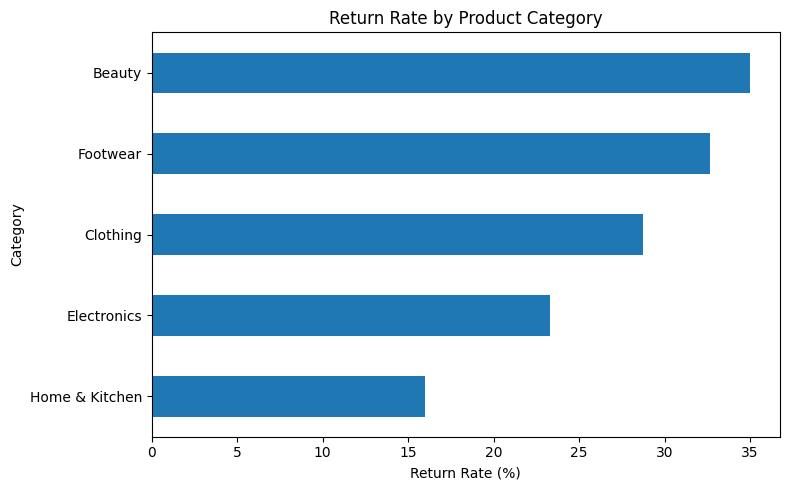

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

category_returns['return_rate'].sort_values().plot(
    kind='barh', figsize=(8, 5)
)

plt.title('Return Rate by Product Category')
plt.xlabel('Return Rate (%)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()


,count
return_reason,
Wrong Size,43
Not as Described,23
Late Delivery,22
Changed Mind,18
Damaged Product,11
Wrong Item,7
Not Specified,6


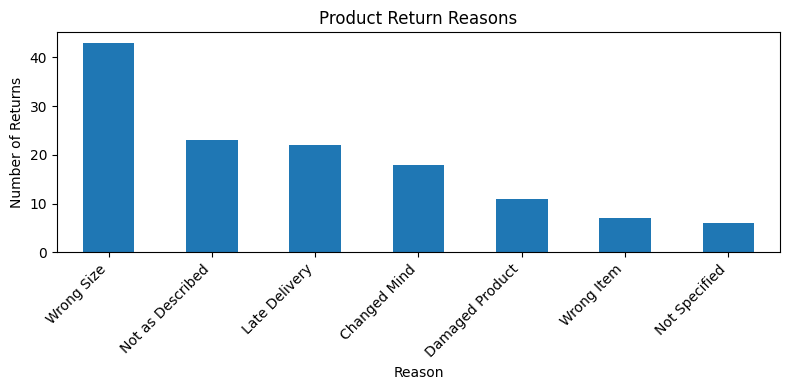

In [13]:
q
reason_counts = returns['return_reason'].value_counts()

display(reason_counts)

reason_counts.plot(kind='bar', figsize=(8, 4))
plt.title('Product Return Reasons')
plt.xlabel('Reason')
plt.ylabel('Number of Returns')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [14]:

seller_analysis = data.groupby('seller_id').agg(
    total_orders=('order_id', 'nunique'),
    returned_orders=('return_flag', 'sum')
)

seller_analysis['return_rate'] = (
    seller_analysis['returned_orders'] /
    seller_analysis['total_orders'] * 100
)

display(seller_analysis.sort_values('return_rate', ascending=False))


,total_orders,returned_orders,return_rate
seller_id,,,
SELLER_011,4,3,75.000000
SELLER_012,29,12,41.379310
SELLER_009,24,9,37.500000
SELLER_008,19,6,31.578947
SELLER_001,38,12,31.578947
SELLER_005,52,15,28.846154
SELLER_010,28,8,28.571429
SELLER_006,32,9,28.125000
SELLER_013,22,6,27.272727


In [17]:

# Customer segment return analysis

customer_analysis = data.groupby('customer_segment').agg(
    total_orders=('order_id', 'nunique'),
    returned_orders=('return_flag', 'sum')
)

customer_analysis['return_rate'] = (
    customer_analysis['returned_orders'] /
    customer_analysis['total_orders'] * 100
)

display(customer_analysis)


,total_orders,returned_orders,return_rate
customer_segment,,,
Loyal,120,34,28.333333
New,140,36,25.714286
Returning,240,60,25.000000


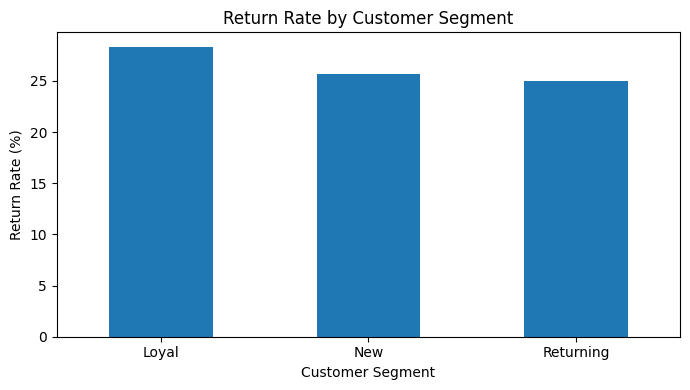

In [18]:

customer_analysis['return_rate'].plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Return Rate by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Return Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [19]:

data['is_late_delivery'] = (
    data['delivery_delay'] > 0
).astype(int)

data['order_value'] = (
    data['quantity'] * data['price'] *
    (1 - data['discount'] / 100)
)

display(data[['order_id', 'order_value', 'delivery_delay',
              'is_late_delivery', 'return_flag']].head())


,order_id,order_value,delivery_delay,is_late_delivery,return_flag
0,O00001,2265.525,2.0,1,0
1,O00002,1819.611,2.0,1,0
2,O00003,3422.496,7.0,1,1
3,O00004,6712.864,-1.0,0,0
4,O00005,4275.000,7.0,1,1


In [20]:

print("Highest return-rate category:")
print(category_returns['return_rate'].idxmax())

print("\nMost common return reason:")
print(returns['return_reason'].value_counts().idxmax())

print("\nCustomer segment with highest return rate:")
print(customer_analysis['return_rate'].idxmax())


Highest return-rate category:
Beauty

Most common return reason:
Wrong Size

Customer segment with highest return rate:
Loyal


In [21]:

from google.colab import files

data.to_csv('/content/final_ecommerce_returns.csv', index=False)

files.download('/content/final_ecommerce_returns.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>